# Getting the data

In [6]:
import pandas as pd
df = pd.read_csv("data/social_media_sentiment_raw.csv")
print("Rows, columns:", df.shape)
display(df.head())
df.info()
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum())

Rows, columns: (2260, 13)


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260 entries, 0 to 2259
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2260 non-null   object 
 1   timestamp        2260 non-null   object 
 2   platform         2260 non-null   object 
 3   user             2260 non-null   object 
 4   followers_count  2170 non-null   object 
 5   verified         2216 non-null   object 
 6   text             2260 non-null   object 
 7   hashtags         1472 non-null   object 
 8   country          2134 non-null   object 
 9   likes            2260 non-null   int64  
 10  retweets_shares  2260 non-null   int64  
 11  comments         2214 non-null   float64
 12  sentiment        2227 non-null   object 
dtypes: float64(1), int64(2), object(10)
memory usage: 229.7+ KB
Duplicate rows: 44


post_id              0
timestamp            0
platform             0
user                 0
followers_count     90
verified            44
text                 0
hashtags           788
country            126
likes                0
retweets_shares      0
comments            46
sentiment           33
dtype: int64

# Inspecting the data

In [ ]:
raw = df.copy()  

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate post_ids:", df["post_id"].duplicated().sum())
dups = df[df.duplicated(keep=False)].sort_values("post_id")
display(dups.head(6))


print("Missing verified AND duplicated:", (df["verified"].isna() & df.duplicated()).sum())

for col in ["platform", "verified", "country", "sentiment"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

print("\nfollowers_count sample of non-numeric values:")
fc = pd.to_numeric(df["followers_count"], errors="coerce")
display(df.loc[fc.isna() & df["followers_count"].notna(), "followers_count"].head(10))

print("\nNegative values:")
print("likes < 0:", (df["likes"] < 0).sum(),
      "| shares < 0:", (df["retweets_shares"] < 0).sum(),
      "| comments < 0:", (df["comments"] < 0).sum())

ts = pd.to_datetime(df["timestamp"], errors="coerce")
print("\nBad timestamps:", ts.isna().sum(), "| range:", ts.min(), "to", ts.max())

display(df[["likes", "retweets_shares", "comments"]].describe())

Exact duplicate rows: 44
Duplicate post_ids: 60


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
1366,P100002,2023-06-13 15:23:12,Facebook,avery_116,586.0,No,"Best platform experience ever, highly recommen...",#Sports #Art #Gaming,NaN,19,4,0.0,Positive
265,P100002,2023-06-13 15:23:12,Facebook,avery_116,586.0,No,"Best platform experience ever, highly recommen...",#Sports #Art #Gaming,NaN,19,4,0.0,Positive
945,P100110,2024-10-10 03:39:33,LinkedIn,liam_1622,326.0,No,"Best policy experience ever, highly recommend ...",NaN,NaN,21,3,3.0,Positive
2041,P100110,2024-10-10 03:39:33,LinkedIn,liam_1622,326.0,No,"Best policy experience ever, highly recommend ...",NaN,NaN,21,3,3.0,Positive
1473,P100196,2024-07-09 10:34:18,Facebook,sam_9021,2415.0,No,"Just checked out the new community feature, st...",#Business #Art,NaN,28,6,3.0,Neutral
1648,P100196,2024-07-09 10:34:18,Facebook,sam_9021,2415.0,No,"Just checked out the new community feature, st...",#Business #Art,NaN,28,6,3.0,Neutral


Missing verified AND duplicated: 0

--- platform ---
platform
Twitter      691
Instagram    561
TikTok       357
Facebook     352
LinkedIn     118
TWITTER       54
INSTAGRAM     53
TIKTOK        41
FACEBOOK      27
LINKEDIN       6
Name: count, dtype: int64

--- verified ---
verified
No     2024
Yes     192
NaN      44
Name: count, dtype: int64

--- country ---
country
USA               433
India             367
UK                202
Canada            164
Australia         156
Germany           143
NaN               126
UAE               110
France            104
Japan             101
Brazil            101
South Africa       78
Mexico             49
usa                33
india              22
uk                 15
canada             12
australia           8
uae                 7
brazil              6
germany             6
japan               5
france              4
south africa        4
mexico              4
Name: count, dtype: int64

--- sentiment ---
sentiment
Positive    907
Neutral

73      1,125
146     2,749
250     1,412
272     9,876
323    20,454
377     4,789
409     1,692
469     7,189
473    29,772
560     1,519
Name: followers_count, dtype: object


Negative values:
likes < 0: 8 | shares < 0: 0 | comments < 0: 0

Bad timestamps: 0 | range: 2023-01-01 01:08:09 to 2024-12-31 21:11:13


,likes,retweets_shares,comments
count,2260.00000,2260.000000,2214.000000
mean,35.94646,6.617699,3.448509
std,16.56231,4.721631,2.745874
min,-1.00000,0.000000,0.000000
25%,25.00000,3.000000,1.000000
50%,33.00000,6.000000,3.000000
75%,44.00000,9.000000,5.000000
max,126.00000,37.000000,20.000000


# Cleaning Data

In [ ]:
clean = raw.copy()

# 1. Standardize text columns
for col in ["platform", "country", "verified", "sentiment"]:
    clean[col] = clean[col].astype("string").str.strip()
clean["platform"] = clean["platform"].str.title()          
clean["sentiment"] = clean["sentiment"].str.title()
clean["verified"] = clean["verified"].str.title()
clean["country"] = clean["country"].str.title()
clean["country"] = clean["country"].replace({"Usa": "USA", "Uk": "UK", "Uae": "UAE"})

# 2. Fix types
clean["followers_count"] = pd.to_numeric(
    clean["followers_count"].astype("string").str.replace(",", "", regex=False),
    errors="coerce")
clean["timestamp"] = pd.to_datetime(clean["timestamp"])

# 3. Duplicates (check again after standardizing)
print("Exact duplicates after standardizing:", clean.duplicated().sum())
clean = clean.drop_duplicates().reset_index(drop=True)

# 4. Look at the remaining duplicate post_ids
rest = clean[clean["post_id"].duplicated(keep=False)].sort_values("post_id")
print("Rows still sharing a post_id:", len(rest))
display(rest.head(8))

# 5. Invalid values
clean.loc[clean["likes"] < 0, "likes"] = pd.NA
clean["likes"] = clean["likes"].astype("float64")

# 6. Missing values: label, don't delete
for col in ["verified", "country", "sentiment"]:
    clean[col] = clean[col].fillna("Unknown")
clean["hashtag_count"] = clean["hashtags"].fillna("").str.count("#")

# 7. Derived columns
clean["day_of_week"] = clean["timestamp"].dt.day_name()
clean["month"] = clean["timestamp"].dt.to_period("M").astype(str)

print("\nBefore:", raw.shape, "| After:", clean.shape)
print(clean["platform"].value_counts())
print(clean["country"].value_counts().head(15))
display(clean.isna().sum())

Exact duplicates after standardizing: 60
Rows still sharing a post_id: 0


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment



Before: (2260, 13) | After: (2200, 16)
platform
Twitter      726
Instagram    595
Tiktok       390
Facebook     370
Linkedin     119
Name: count, dtype: Int64
country
USA             466
India           389
UK              217
Canada          176
Australia       164
Germany         149
UAE             117
France          108
Brazil          107
Japan           106
South Africa     82
Unknown          66
Mexico           53
Name: count, dtype: Int64


post_id              0
timestamp            0
platform             0
user                 0
followers_count     88
verified             0
text                 0
hashtags           762
country              0
likes                8
retweets_shares      0
comments            44
sentiment            0
hashtag_count        0
day_of_week          0
month                0
dtype: int64

# EDA

,posts,mean_likes,median_likes,mean_comments,median_comments,median_total
platform,,,,,,
TikTok,390,47.35,44.0,4.61,4.0,56.0
Instagram,595,39.01,37.0,3.81,3.0,46.0
Twitter,726,34.04,32.0,3.19,3.0,40.0
Facebook,370,28.32,26.0,2.65,2.0,34.0
LinkedIn,119,21.22,20.0,1.94,2.0,24.5


,posts,mean_likes,median_likes,median_comments
sentiment,,,,
Negative,636,33.66,32.0,3.0
Neutral,652,30.32,28.0,2.0
Positive,879,42.11,39.0,3.0
Unknown,33,36.39,32.0,3.0



Correlations:


,likes,retweets_shares,comments
likes,1.00,0.68,0.66
retweets_shares,0.68,1.00,0.46
comments,0.66,0.46,1.00


Top 10% of posts hold 20.4% of all likes


,platform,sentiment,likes,retweets_shares,comments
2160,Twitter,Positive,126.0,28,15.0
1120,Twitter,Positive,120.0,23,4.0
702,Instagram,Positive,117.0,19,13.0
40,TikTok,Neutral,114.0,28,9.0
1302,Instagram,Positive,114.0,28,17.0


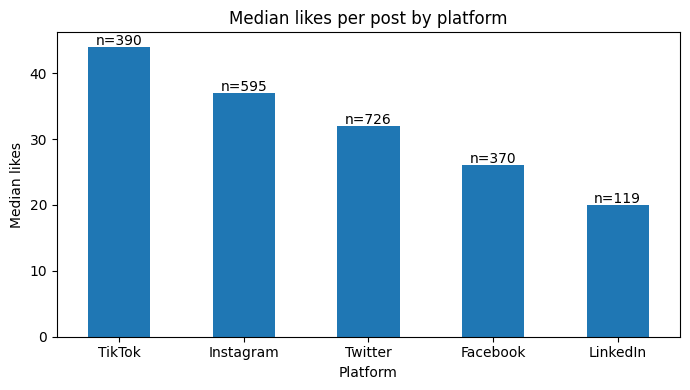

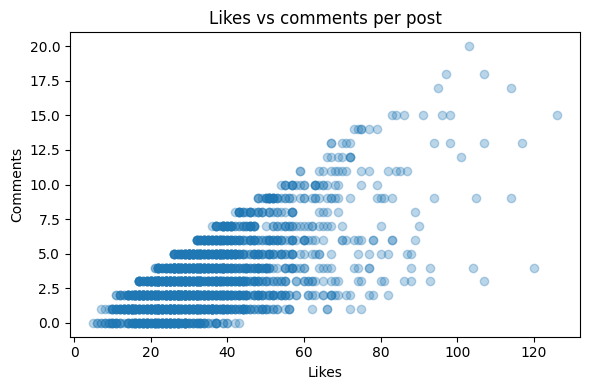

In [ ]:
import os
import matplotlib.pyplot as plt
os.makedirs("charts", exist_ok=True)

clean["platform"] = clean["platform"].replace({"Tiktok": "TikTok", "Linkedin": "LinkedIn"})

# Total engagement only where all three metrics exist
clean["total_engagement"] = clean[["likes", "retweets_shares", "comments"]].sum(axis=1, min_count=3)

# STAT 1: engagement by platform (with group sizes)
by_platform = clean.groupby("platform").agg(
    posts=("post_id", "count"),
    mean_likes=("likes", "mean"), median_likes=("likes", "median"),
    mean_comments=("comments", "mean"), median_comments=("comments", "median"),
    median_total=("total_engagement", "median")
).round(2).sort_values("median_likes", ascending=False)
display(by_platform)

# STAT 2: engagement by sentiment (with group sizes)
by_sent = clean.groupby("sentiment").agg(
    posts=("post_id", "count"),
    mean_likes=("likes", "mean"), median_likes=("likes", "median"),
    median_comments=("comments", "median")
).round(2)
display(by_sent)

# Extra checks
print("\nCorrelations:")
display(clean[["likes", "retweets_shares", "comments"]].corr().round(2))
top10 = clean["likes"].quantile(0.90)
share = clean.loc[clean["likes"] >= top10, "likes"].sum() / clean["likes"].sum()
print(f"Top 10% of posts hold {share:.1%} of all likes")
display(clean.nlargest(5, "likes")[["platform", "sentiment", "likes", "retweets_shares", "comments"]])

# CHART 1: median likes by platform, with n on each bar
order = by_platform.index
ax = by_platform["median_likes"].plot(kind="bar", figsize=(7, 4))
for i, plat in enumerate(order):
    ax.text(i, by_platform.loc[plat, "median_likes"] + 0.3,
            f"n={by_platform.loc[plat, 'posts']}", ha="center")
plt.title("Median likes per post by platform")
plt.xlabel("Platform"); plt.ylabel("Median likes")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("charts/median_likes_by_platform.png", dpi=150)
plt.show()

# CHART 2: likes vs comments
plt.figure(figsize=(6, 4))
plt.scatter(clean["likes"], clean["comments"], alpha=0.3)
plt.title("Likes vs comments per post")
plt.xlabel("Likes"); plt.ylabel("Comments")
plt.tight_layout()
plt.savefig("charts/likes_vs_comments.png", dpi=150)
plt.show()

# Follow check and scaling 

In [ ]:
import time, os, psutil

# Audience Check
clean["likes_per_1k_followers"] = clean["likes"] / clean["followers_count"] * 1000
chk = clean.groupby("platform").agg(
    posts=("post_id", "count"),
    median_followers=("followers_count", "median"),
    median_likes_per_1k=("likes_per_1k_followers", "median")
).round(2)
display(chk)
print("Correlation likes vs followers:",
      round(clean["likes"].corr(clean["followers_count"]), 2))

# Scaling
def analyze(d):
    g = d.groupby("platform").agg(mean_likes=("likes", "mean"),
                                  median_likes=("likes", "median"),
                                  median_comments=("comments", "median"))
    s = d.groupby("sentiment")["likes"].median()
    c = d[["likes", "retweets_shares", "comments"]].corr()
    return g, s, c

proc = psutil.Process()
rows = []
for factor in [1, 10, 100, 1000]:
    try:
        big = pd.concat([clean] * factor, ignore_index=True)
        path = f"scaling_{factor}x.csv"
        big.to_csv(path, index=False)
        size_mb = os.path.getsize(path) / 1e6
        del big

        t0 = time.perf_counter(); d = pd.read_csv(path); t_load = time.perf_counter() - t0
        t0 = time.perf_counter(); analyze(d); t_an = time.perf_counter() - t0
        t0 = time.perf_counter(); d.drop_duplicates(); t_dup = time.perf_counter() - t0

        rows.append({"workload": f"{factor}x", "rows": len(d), "file_MB": round(size_mb, 1),
                     "load_s": round(t_load, 2), "analysis_s": round(t_an, 2),
                     "dedupe_s": round(t_dup, 2),
                     "df_memory_MB": round(d.memory_usage(deep=True).sum() / 1e6, 1),
                     "process_RAM_MB": round(proc.memory_info().rss / 1e6)})
        del d
        os.remove(path)
    except MemoryError:
        rows.append({"workload": f"{factor}x", "rows": "MemoryError"})
        break

results = pd.DataFrame(rows)
display(results)
results.to_csv("scaling_results.csv", index=False)

,posts,median_followers,median_likes_per_1k
platform,,,
Facebook,370,2180.0,12.72
Instagram,595,1612.0,22.7
LinkedIn,119,2153.0,10.54
TikTok,390,1474.0,27.97
Twitter,726,1784.5,17.06


Correlation likes vs followers: 0.3


,workload,rows,file_MB,load_s,analysis_s,dedupe_s,df_memory_MB,process_RAM_MB
0,1x,2200,0.4,0.10,0.05,0.01,1.8,151
1,10x,22000,4.3,0.17,0.05,0.09,17.9,155
2,100x,220000,43.4,1.04,0.11,0.44,179.5,187
3,1000x,2200000,434.0,10.30,0.84,3.58,1794.5,503


In [15]:

display(clean.pivot_table(index="platform", columns="sentiment",
                          values="likes", aggfunc="median").round(1))
display(pd.crosstab(clean["platform"], clean["sentiment"], normalize="index").round(2))

# Saving
print(sorted(os.listdir(".")))   

sentiment,Negative,Neutral,Positive,Unknown
platform,,,,
Facebook,25.5,22.0,32.0,31.0
Instagram,36.0,31.0,42.0,27.0
LinkedIn,17.0,17.0,24.5,NaN
TikTok,43.0,39.0,51.0,57.0
Twitter,30.0,26.0,37.0,29.0


sentiment,Negative,Neutral,Positive,Unknown
platform,,,,
Facebook,0.27,0.31,0.41,0.02
Instagram,0.30,0.32,0.37,0.02
LinkedIn,0.32,0.29,0.39,0.00
TikTok,0.30,0.29,0.39,0.01
Twitter,0.28,0.27,0.43,0.02


['.gitignore', 'charts', 'data', 'data_dictionary.md', 'project1_social_media_analysis.ipynb', 'scaling_results.csv']


Finding 1: TikTok posts get the most engagement, and LinkedIn the least.

Evidence: median likes are 44 (TikTok, n=390) vs 20 (LinkedIn, n=119). The ranking is the same for median comments and total engagement. After adjusting for audience, TikTok still leads with 27.97 median likes per 1,000 followers vs 10.54 for LinkedIn, even though TikTok accounts are the smallest (median 1,474 followers).
Action: test more short-form TikTok content and compare it to current channels using likes per 1,000 followers.
Limitation: the 88 posts with missing follower counts are excluded from the adjusted comparison. The data is multi-platform and not specific to Pakistani brands.

Finding 2: positive-sentiment posts get more likes than negative or neutral ones, on every platform.

Evidence: overall median likes are 39 (positive, n=879), 32 (negative, n=636) and 28 (neutral, n=652). The same order appears within each platform, and the sentiment mix is similar across platforms.
Action: A/B test positive-toned captions against neutral ones on the same platform.
Limitation: this is an association, not proof of cause. We don’t know how the sentiment labels were produced, and the text looks templated, so the data may be synthetic.